# Step - 1 connecting project files

In [ ]:
import subprocess
from pathlib import Path

REPO_URL = "https://github.com/rishitha-2602/traffic-accident-risk-analytics.git"
PROJECT_DIR = Path("/content/traffic-accident-risk-analytics")

if not PROJECT_DIR.exists():
    result = subprocess.run(
        ["git", "clone", REPO_URL, str(PROJECT_DIR)],
        capture_output=True,
        text=True
    )
    print(result.stdout)
    if result.returncode != 0:
        print(result.stderr)
        raise RuntimeError("Repository clone failed. Check the GitHub URL.")

print("Project exists:", PROJECT_DIR.exists())
print("Notebooks folder:", (PROJECT_DIR / "notebooks").exists())
print("Reports folder:", (PROJECT_DIR / "reports").exists())


Project exists: True
Notebooks folder: True
Reports folder: True


# Step 2 — Load the saved results

In [ ]:
import pandas as pd
from pathlib import Path

REPORT_DIR = PROJECT_DIR / "reports"

for filename in [
    "cleaning_summary.csv",
    "eda_severity_distribution.csv",
    "eda_monthly_crash_counts.csv",
    "eda_date_coverage.csv",
    "eda_data_quality.csv",
]:
    path = REPORT_DIR / filename

    print(f"\n{'=' * 60}")
    print(filename)

    if path.exists():
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        display(df.head())
    else:
        print("File not found")


cleaning_summary.csv
Shape: (5, 8)


,year,original_rows,processed_rows,rows_removed,unique_crash_ids,missing_crash_ids,missing_dates,severity_codes_not_in_lookup
0,2021,97947,97947,0,97947,0,0,0
1,2022,94700,94700,0,94700,0,0,0
2,2023,92082,92082,0,92082,0,0,0
3,2024,83092,83092,0,83092,0,0,0
4,2025,82670,82670,0,82670,0,0,1



eda_severity_distribution.csv
Shape: (7, 3)


,Crash_Sev_ID,Crash_Count,Percentage
0,0,30180,6.70
1,1,12322,2.74
2,2,62226,13.81
3,3,69741,15.48
4,4,2565,0.57



eda_monthly_crash_counts.csv
Shape: (12, 6)


,Crash_Month,2021,2022,2023,2024,2025
0,1,7552,7576,7564,6791,6054
1,2,6189,7136,6712,6961,5796
2,3,7907,8113,7888,7129,7001
3,4,8332,8138,7730,6959,7054
4,5,8975,8419,7966,7444,7292



eda_date_coverage.csv
Shape: (5, 6)


,Year,Records,Earliest_Date,Latest_Date,Months_Represented,Invalid_Dates
0,2021,97947,2021-01-01,2021-12-31,12,0
1,2022,94700,2022-01-01,2022-12-31,12,0
2,2023,92082,2023-01-01,2023-12-31,12,0
3,2024,83092,2024-01-01,2024-12-31,12,0
4,2025,82670,2025-01-01,2025-12-31,12,0



eda_data_quality.csv
Shape: (5, 8)


,Year,Rows,Columns,Exact_Duplicate_Rows,Missing_Cells,Missing_Crash_IDs,Unique_Crash_IDs,Duplicate_Crash_IDs
0,2021,97947,175,0,7375942,0,97947,0
1,2022,94700,175,0,7180877,0,94700,0
2,2023,92082,184,0,7152179,0,92082,0
3,2024,83092,184,0,6224793,0,83092,0
4,2025,82670,184,0,6194748,0,82670,0


# Step 3 — Create dashboard heading

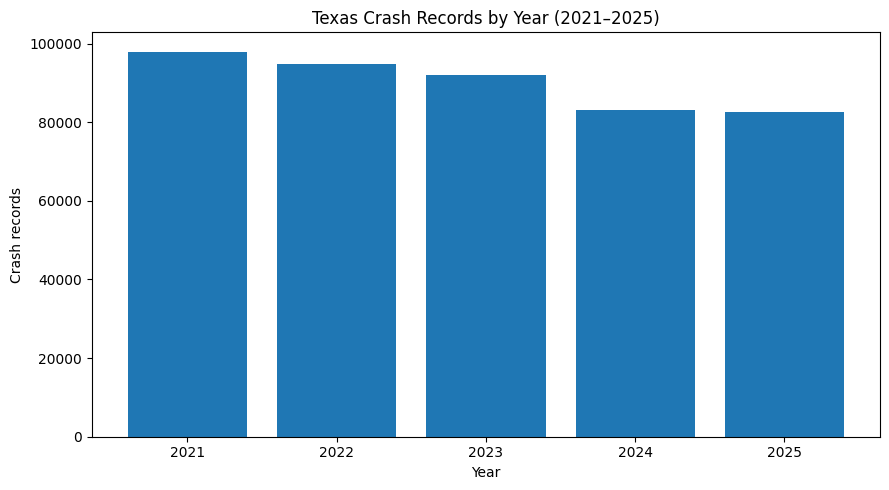

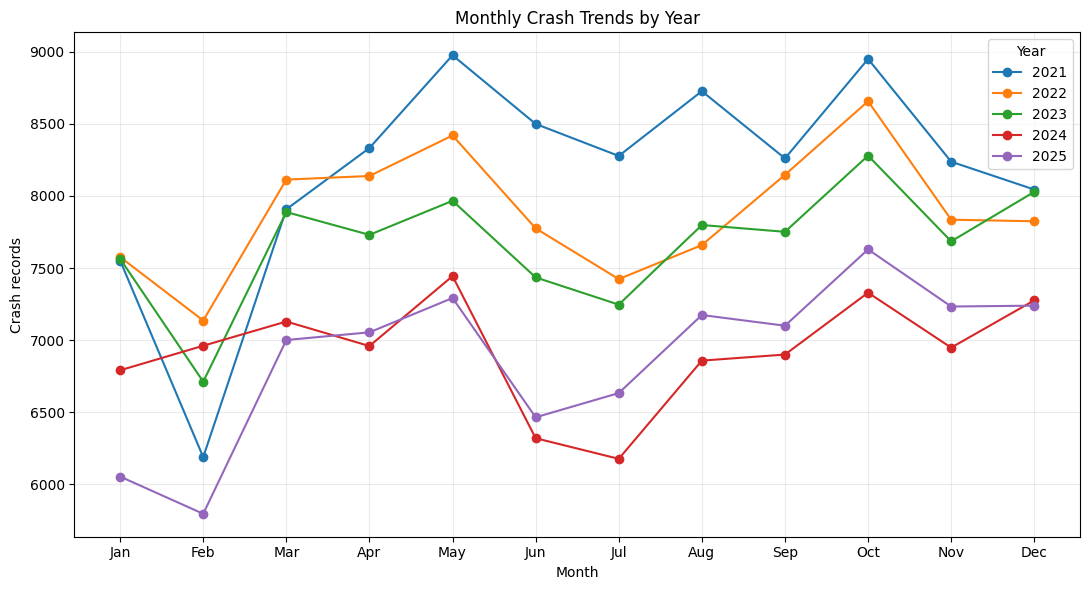

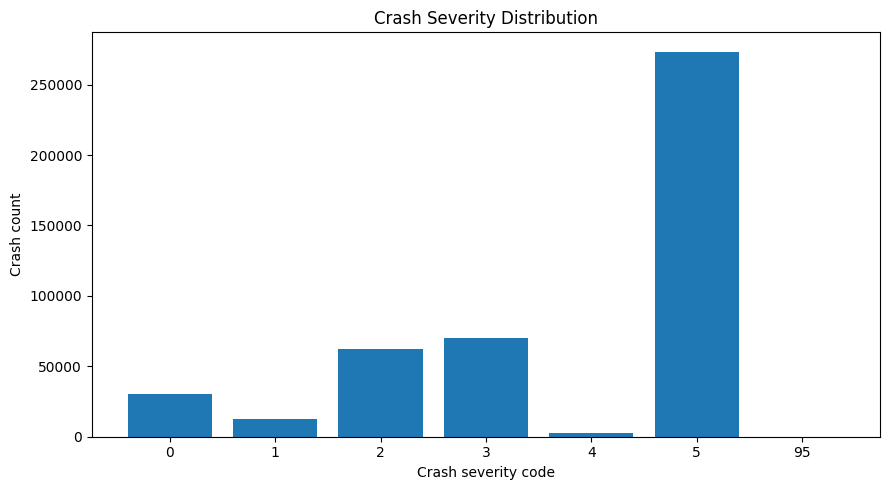

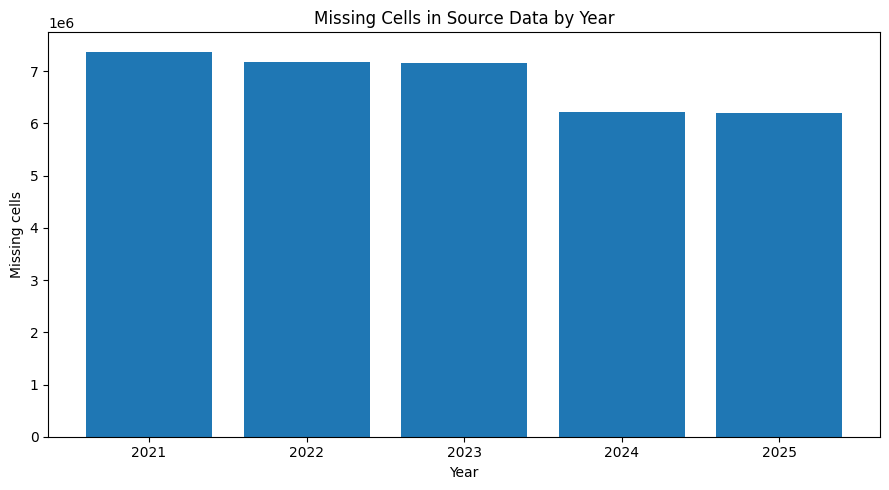


Charts saved successfully in: /content/traffic-accident-risk-analytics/reports/dashboard
missing_cells_by_year.png — 28,628 bytes
monthly_crash_trends.png — 209,024 bytes
severity_distribution.png — 36,909 bytes
yearly_crash_records.png — 36,903 bytes


In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Set project and report paths
PROJECT_DIR = Path("/content/traffic-accident-risk-analytics")
REPORT_DIR = PROJECT_DIR / "reports"
DASHBOARD_DIR = REPORT_DIR / "dashboard"
DASHBOARD_DIR.mkdir(parents=True, exist_ok=True)

# Check required files
required_files = [
    "cleaning_summary.csv",
    "eda_monthly_crash_counts.csv",
    "eda_severity_distribution.csv",
    "eda_data_quality.csv",
]

missing = [f for f in required_files if not (REPORT_DIR / f).exists()]
if missing:
    raise FileNotFoundError(f"Missing report files: {missing}")

# Chart 1: Yearly crash records
cleaning = pd.read_csv(REPORT_DIR / "cleaning_summary.csv")

plt.figure(figsize=(9, 5))
plt.bar(cleaning["year"].astype(str), cleaning["processed_rows"])
plt.title("Texas Crash Records by Year (2021–2025)")
plt.xlabel("Year")
plt.ylabel("Crash records")
plt.tight_layout()
plt.savefig(DASHBOARD_DIR / "yearly_crash_records.png", dpi=160)
plt.show()

# Chart 2: Monthly crash trends
monthly = pd.read_csv(REPORT_DIR / "eda_monthly_crash_counts.csv")

plt.figure(figsize=(11, 6))
for year in ["2021", "2022", "2023", "2024", "2025"]:
    if year in monthly.columns:
        plt.plot(
            monthly["Crash_Month"],
            monthly[year],
            marker="o",
            label=year
        )

plt.xticks(
    range(1, 13),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)
plt.title("Monthly Crash Trends by Year")
plt.xlabel("Month")
plt.ylabel("Crash records")
plt.legend(title="Year")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(DASHBOARD_DIR / "monthly_crash_trends.png", dpi=160)
plt.show()

# Chart 3: Severity distribution (all severity codes)
severity = pd.read_csv(REPORT_DIR / "eda_severity_distribution.csv")

plt.figure(figsize=(9, 5))
plt.bar(severity["Crash_Sev_ID"].astype(str), severity["Crash_Count"])
plt.title("Crash Severity Distribution")
plt.xlabel("Crash severity code")
plt.ylabel("Crash count")
plt.tight_layout()
plt.savefig(DASHBOARD_DIR / "severity_distribution.png", dpi=160)
plt.show()

# Chart 4: Missing cells by year
quality = pd.read_csv(REPORT_DIR / "eda_data_quality.csv")

plt.figure(figsize=(9, 5))
plt.bar(quality["Year"].astype(str), quality["Missing_Cells"])
plt.title("Missing Cells in Source Data by Year")
plt.xlabel("Year")
plt.ylabel("Missing cells")
plt.tight_layout()
plt.savefig(DASHBOARD_DIR / "missing_cells_by_year.png", dpi=160)
plt.show()

print("\nCharts saved successfully in:", DASHBOARD_DIR)
for file in sorted(DASHBOARD_DIR.glob("*.png")):
    print(f"{file.name} — {file.stat().st_size:,} bytes")